# B1: Predict Uber fare, Linear Regression vs Random Forest



## Import libraries

In [1]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, root_mean_squared_error

## Step 1: Pre-process

In [2]:
df = pd.read_csv("uber.csv")
df = df.drop(columns=["Unnamed: 0", "key", "pickup_datetime"]).dropna()

## Step 2: Identify outliers (boxplot) and remove them (IQR rule)

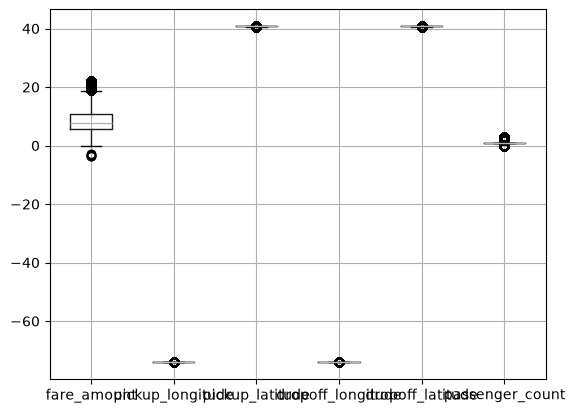

In [3]:
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1
df = df[~((df < Q1 - 1.5 * IQR) | (df > Q3 + 1.5 * IQR)).any(axis=1)]
df.boxplot()

## Step 3: Check the correlation

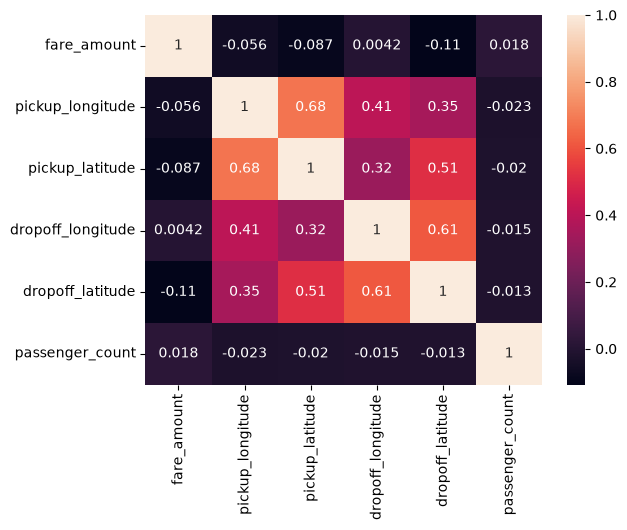

In [4]:
sns.heatmap(df.corr(), annot=True)

## Step 4: Train both models, evaluate R2 and RMSE

In [5]:
X = df.drop(columns=["fare_amount"])
y = df["fare_amount"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

for model in [LinearRegression(), RandomForestRegressor()]:
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(model)
    print("R2:", r2_score(y_test, y_pred))
    print("RMSE:", root_mean_squared_error(y_test, y_pred))

LinearRegression()
R2: 0.02066864807094937
RMSE: 3.897488395401701
RandomForestRegressor()
R2: 0.7137153093338169
RMSE: 2.107264563240351
